# 3. The lasso when p >> n: sparsity, correlated genes, instability

**Learning goals**: why the lasso selects at most n genes, why its gene list changes from sample to
sample, and how to report it honestly (selection frequencies, stability selection).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(7)

In [2]:
# The project's data: one drug, its screened cell lines, 2,000 most variable genes
from drugresponse.experiment import Store
from drugresponse.models import Design
S = Store()
drug_name = "Nutlin-3a (-)"
d = S.drugs.index[S.drugs.drug_name == drug_name][0]
ok = S.R[d].notna().values
des = Design(2000).fit(S.Ev[ok], S.tissue[ok], S.sanger[ok])
X = des.transform(S.Ev[ok], S.tissue[ok], S.sanger[ok])[:, ~des.is_tissue()]   # genes only
y = S.R[d].values[ok]
genes = S.genes[des.genes_]
print(f"{drug_name}: {X.shape[0]} cell lines x {X.shape[1]} genes")

Nutlin-3a (-): 943 cell lines x 2000 genes


first genes to enter: ['INPP5D', 'NHSL3', 'PURPL', 'CDKN1A', 'CDKN2A', 'ID1', 'CYFIP2', 'TRIM22', 'RIPK4', 'ITGAL']


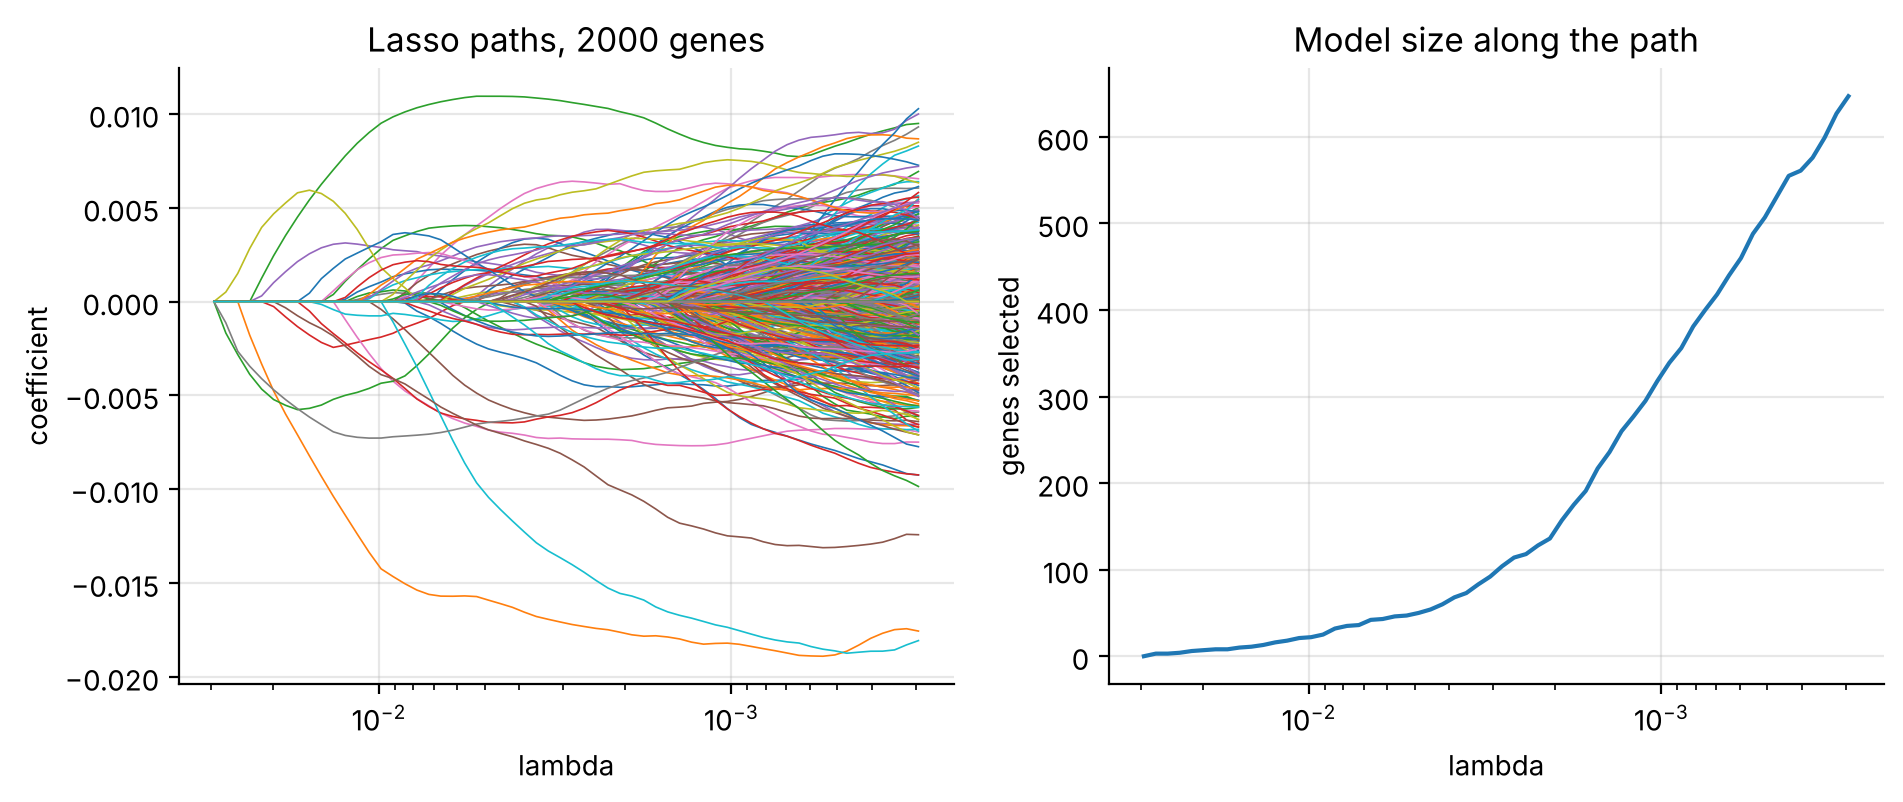

In [3]:
from sklearn.linear_model import lasso_path
alphas, coefs, _ = lasso_path(X - X.mean(0), y - y.mean(), n_alphas=60, eps=1e-2)
nnz = (np.abs(coefs) > 0).sum(0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(alphas, coefs.T, lw=0.6); ax[0].set_xscale("log"); ax[0].invert_xaxis()
ax[0].set(xlabel="lambda", ylabel="coefficient", title=f"Lasso paths, {X.shape[1]} genes")
ax[1].plot(alphas, nnz); ax[1].set_xscale("log"); ax[1].invert_xaxis()
ax[1].set(xlabel="lambda", ylabel="genes selected", title="Model size along the path");
first = [genes[j] for j in np.argsort([np.argmax(np.abs(coefs[j]) > 0) if np.any(coefs[j]) else 999 for j in range(len(genes))])[:10]]
print("first genes to enter:", first)

Nutlin-3a blocks MDM2, which only kills cells whose **TP53** is intact. Wild-type TP53 switches on
its target genes, such as **MDM2**, **CDKN1A** (p21), **EDA2R**, **SPATA18** and **RPS27L**, so
high expression of those genes marks lines that respond. If the first genes to enter are TP53 targets,
the lasso has found real biology from expression alone.

## Selection is unstable
Refit on 20 random subsamples of 80% of the lines and count how often each gene is chosen.

In [4]:
from sklearn.linear_model import LassoCV
counts = pd.Series(0, index=genes, dtype=float); sizes = []
for b in range(20):
    idx = rng.choice(len(y), int(0.8 * len(y)), replace=False)
    m = LassoCV(cv=3, alphas=20, eps=1e-2, max_iter=2000, tol=1e-3, precompute=True).fit(X[idx], y[idx])
    sel = genes[np.abs(m.coef_) > 0]; counts[sel] += 1; sizes.append(len(sel))
freq = counts / 20
print(f"genes selected per fit: median {np.median(sizes):.0f}")
print(f"selected in >= 90% of fits: {(freq >= 0.9).sum()};  in 10-90%: {((freq > 0.1) & (freq < 0.9)).sum()}")
freq.sort_values(ascending=False).head(15).round(2)

genes selected per fit: median 88
selected in >= 90% of fits: 27;  in 10-90%: 163


TRIM22       1.0
GPNMB        1.0
INHBE        1.0
JUN          1.0
ACTA2        1.0
PAX6         1.0
CDKN1A       1.0
CDKN2A       1.0
CACNA2D4     1.0
CD82         1.0
PHLDA3       1.0
GABARAPL1    1.0
PURPL        1.0
PPP1R13L     1.0
MOK          1.0
dtype: float64

A small core of genes is chosen almost every time, and a long tail flickers in and out. Among
correlated genes the lasso tends to pick one, more or less at random. **Stability selection**
(Meinshausen and Bühlmann, 2010) keeps genes chosen in a high share of subsamples. The project
reports selection frequency across the five outer folds for the same reason.

**Key takeaways**
* The lasso can select at most n variables when p > n, and usually far fewer.
* A single lasso fit's gene list is not a finding; its stable core may be.
* Prediction accuracy and selection stability are different goals; the lasso can do well at the
  first while being poor at the second.